# 04 - Embeddings con modelos preentrenados
**Proyecto 2 - CGIAR Eyes on the Ground**

Este notebook está pensado para correr en **Google Colab con GPU**. Pasa las fotos de 224×224 (notebook 03) por ResNet50 y EfficientNet-B0, preentrenadas en ImageNet, y guarda el vector de características de cada foto. Esos vectores se usan después para entrenar modelos clásicos (notebook 05) sin volver a tocar las imágenes.



## 1. Configuración

In [8]:
import sys
import subprocess
import time
import zipfile
import shutil
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules

# ---------- Ajustar estos valores ----------
REPO_URL = "https://github.com/Emadlgg/proyecto2_Data.git"
CARPETA_DRIVE = "Proyecto2-CGIAR"   # carpeta de Drive con images_224.zip e imagenes_meta.csv
LIMITE = None                       # un número (por ejemplo 300) para una prueba rápida
PESOS_PREENTRENADOS = True          # solo se pone en False para pruebas del código
BATCH = 128
# --------------------------------------------

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    if not Path("/content/repo").exists():
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)

    RAIZ = Path("/content/repo")
    DRIVE = Path("/content/drive/MyDrive") / CARPETA_DRIVE
    CARPETA_IMAGENES = Path("/content/images_224")      # disco local de Colab: lee mucho más rápido que Drive
    META = DRIVE / "imagenes_meta.csv"
    SALIDA = DRIVE / "embeddings"
    FIGURAS = DRIVE / "figuras"
    WORKERS = 2
else:
    # Corrida local (por si hay GPU o para probar el código)
    RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
    CARPETA_IMAGENES = RAIZ / "data" / "processed" / "images_224"
    META = RAIZ / "data" / "processed" / "imagenes_meta.csv"
    SALIDA = RAIZ / "data" / "embeddings"
    FIGURAS = RAIZ / "figuras"
    WORKERS = 0

if LIMITE:
    SALIDA = SALIDA / "_prueba"   # las pruebas rápidas no pisan los resultados reales

sys.path.append(str(RAIZ))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from src.embeddings import crear_extractor, extraer_embeddings, EXTRACTORES

sns.set_theme(style="whitegrid")

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", dispositivo)
if dispositivo.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
elif EN_COLAB:
    print("Sin GPU: en Colab, ir a Entorno de ejecución -> Cambiar tipo de entorno -> GPU")

Dispositivo: cuda
GPU: Tesla T4


## 2. Imágenes

En Colab se copia el zip desde Drive al disco local y se descomprime. Leer miles de fotos directo desde Drive es lento, y este paso se hace una sola vez por sesión.

In [10]:
if EN_COLAB and not CARPETA_IMAGENES.exists():
    t0 = time.time()
    shutil.copy(DRIVE / "images_224.zip", "/content/images_224.zip")
    with zipfile.ZipFile("/content/images_224.zip") as zf:
        zf.extractall(CARPETA_IMAGENES)
    print(f"Copiado y descomprimido en {time.time() - t0:.0f} s")

print("Fotos en la carpeta:", len(list(CARPETA_IMAGENES.glob("*.jpg"))))

Fotos en la carpeta: 26068


In [11]:
meta = pd.read_csv(META)
meta = meta[meta["ok"].astype(str).str.lower().eq("true")].reset_index(drop=True)
if LIMITE:
    meta = meta.iloc[:LIMITE].reset_index(drop=True)

faltan = [a for a in meta["archivo_224"] if not (CARPETA_IMAGENES / a).exists()]
assert not faltan, f"Faltan {len(faltan)} fotos en {CARPETA_IMAGENES}"

print("Fotos a procesar:", len(meta))
pd.crosstab(meta["clase4"], meta["split"])

Fotos a procesar: 26068


split,test,train,val
clase4,,,
Bueno,1660,8302,1661
Maleza,1319,6600,1319
Otro daño,100,492,99
Sequía,645,3226,645


## 3. Extraer embeddings

Cada foto pasa por la red sin la capa final de clasificación. El resultado es un vector por foto: 2048 valores con ResNet50 y 1280 con EfficientNet-B0. El orden de las filas es el mismo que el de `indice.csv`.

In [12]:
SALIDA.mkdir(parents=True, exist_ok=True)

columnas_indice = ["ID", "filename", "archivo_224", "damage", "clase4", "split"]
meta[columnas_indice].to_csv(SALIDA / "indice.csv", index=False)

embeddings = {}
for nombre in EXTRACTORES:
    ruta = SALIDA / f"{nombre}.npy"
    if ruta.exists():
        embeddings[nombre] = np.load(ruta)
        print(f"{nombre}: ya existe, se carga {embeddings[nombre].shape}")
        continue

    print(f"\n{nombre}")
    modelo, dim = crear_extractor(nombre, pesos=PESOS_PREENTRENADOS)
    emb = extraer_embeddings(modelo, CARPETA_IMAGENES, meta["archivo_224"], dispositivo,
                             batch=BATCH, workers=WORKERS)
    assert emb.shape == (len(meta), dim)
    np.save(ruta, emb)
    embeddings[nombre] = emb

    del modelo
    if dispositivo.type == "cuda":
        torch.cuda.empty_cache()


resnet50
  2560/26068 fotos | 6 s
  5120/26068 fotos | 11 s
  7680/26068 fotos | 16 s
  10240/26068 fotos | 22 s
  12800/26068 fotos | 27 s
  15360/26068 fotos | 32 s
  17920/26068 fotos | 38 s
  20480/26068 fotos | 43 s
  23040/26068 fotos | 48 s
  25600/26068 fotos | 53 s
  26068/26068 fotos | 54 s

efficientnet_b0
  2560/26068 fotos | 5 s
  5120/26068 fotos | 9 s
  7680/26068 fotos | 14 s
  10240/26068 fotos | 18 s
  12800/26068 fotos | 23 s
  15360/26068 fotos | 27 s
  17920/26068 fotos | 31 s
  20480/26068 fotos | 36 s
  23040/26068 fotos | 40 s
  25600/26068 fotos | 45 s
  26068/26068 fotos | 45 s


## 4. Verificación

In [13]:
for nombre, emb in embeddings.items():
    print(f"{nombre}: forma {emb.shape} | sin NaN/inf: {np.isfinite(emb).all()} | "
          f"norma media: {np.linalg.norm(emb, axis=1).mean():.1f}")

resnet50: forma (26068, 2048) | sin NaN/inf: True | norma media: 14.4
efficientnet_b0: forma (26068, 1280) | sin NaN/inf: True | norma media: 15.7


## 5. Vista rápida de los embeddings

Proyección a 2 dimensiones con PCA de una muestra al azar. No es una prueba de que el modelo vaya a clasificar bien, pero muestra si las clases se separan algo en el espacio de características o si están muy mezcladas.

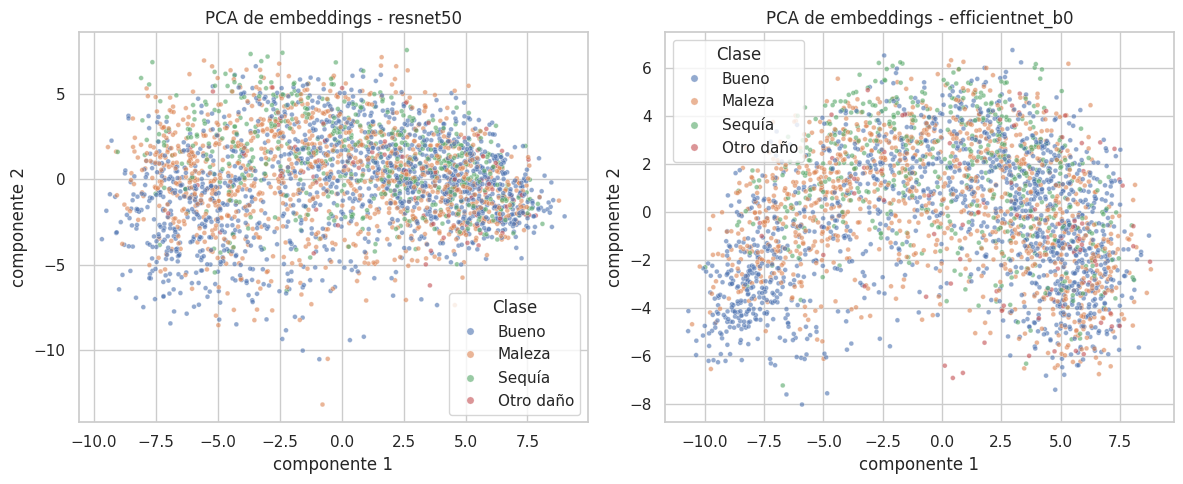

In [14]:
rng = np.random.default_rng(0)
idx = rng.choice(len(meta), size=min(3000, len(meta)), replace=False)
orden = ["Bueno", "Maleza", "Sequía", "Otro daño"]

fig, axes = plt.subplots(1, len(embeddings), figsize=(6 * len(embeddings), 5))
axes = np.atleast_1d(axes)
for ax, (nombre, emb) in zip(axes, embeddings.items()):
    z = PCA(n_components=2, random_state=0).fit_transform(emb[idx])
    sns.scatterplot(x=z[:, 0], y=z[:, 1], hue=meta["clase4"].iloc[idx].values,
                    hue_order=orden, s=12, alpha=0.6, ax=ax)
    ax.set_title(f"PCA de embeddings - {nombre}")
    ax.set_xlabel("componente 1")
    ax.set_ylabel("componente 2")
    ax.legend(title="Clase", markerscale=1.5)
fig.tight_layout()

FIGURAS.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURAS / "embeddings_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## Siguiente paso

En Drive quedan `embeddings/indice.csv`, `embeddings/resnet50.npy` y `embeddings/efficientnet_b0.npy`. Se bajan a `data/embeddings/` en la laptop para entrenar los modelos clásicos en el notebook 05.